<a href="https://colab.research.google.com/github/SergeiVKalinin/Paper_Notebooks/blob/main/VAE_Walls/Main_02_Domains_Packing_Rare_States.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Main 02 — Gaussian domain walls, class packing, and rare states (Figures 2, 4, 5)

All data here are either mathematical functions, synthetic 40×40 prototypes, or the **8×8 digits dataset shipped with scikit-learn**.

The main objective is the quadratic reconstruction and Gaussian KL model; no neural training, external dataset, archived result, or figure-artwork replay is involved. Each plot is saved separately as PNG in `/content`.

The **full rare-state regime diagram** is expensive; use `FAST_MODE=True` for a small numerical diagnostic and `False` for the 18×18 computational sweep. The numerical classifications are lowest-loss results among tested starts, not certified global minima.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# All user-visible output is PNG; nothing is cached or exported in other formats.
OUTPUT = Path('/content') if Path('/content').exists() else Path.cwd()
FAST_MODE = False       # False: use the longer, publication-scale calculations.
DPI = 180 if FAST_MODE else 300

def save_panel(fig, filename):
    fig.savefig(OUTPUT / filename, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved', OUTPUT / filename)

import math
from scipy import optimize, special, integrate
from scipy.special import logsumexp
from scipy.ndimage import gaussian_filter
from sklearn.datasets import load_digits

## Figure 2 — two-class model

With equal class frequencies and Gaussian posteriors, let `k = m²/s²`. The reduced objective is

\[L(k)=R\,g(k)+\tfrac12\log(1+k), \quad g(k)=\mathbb E\,\mathrm{sech}^2(k+\sqrt{k}\,\xi).\]

The sharp-wall asymptote and critical behavior are distinct regimes. We compute the exact one-dimensional quadrature rather than draw precomputed curves.

In [2]:
from __future__ import annotations
from pathlib import Path
from functools import lru_cache
import math, json, re, hashlib, copy
import numpy as np
from scipy import special, optimize, integrate

RC = 0.5
QUADRATURE_ORDER = 256
M0 = 1.0e-4
ONSET_FRACTION = 0.25   # m^2 reaches 1/4 of the instantaneous Landau equilibrium value
PANEL_W, PANEL_H = 5.90, 4.90
AX_RECT = (0.95, 1.25, 4.65, 3.10)  # physical inches: left, bottom, width, height
DPI = 600

@lru_cache(None)
def nodes(order: int):
    x, w = special.roots_legendre(order)
    u, v = special.roots_hermitenorm(order)
    return 20*(x+1), 20*w, u, v/math.sqrt(2*math.pi)

def integrals(k: float, order: int = QUADRATURE_ORDER) -> tuple[float, float]:
    """g(k)=E sech^2(k+sqrt(k)xi); h(k)=E sech^4(...), with g'=-h.

    This is the uploaded notebook's expectation. For k>=1, the equivalent
    boundary-centered integral resolves the small Gaussian-tail contribution.
    Increasing quadrature order changes numerical accuracy, not the model.
    """
    k = float(k)
    if k < 0: raise ValueError('The squared separation k must be nonnegative.')
    if k == 0: return 1.0, 1.0
    x, w, u, v = nodes(order)
    if k < 1:
        a = np.abs(k + math.sqrt(k)*u)
        sech = 2*np.exp(-a)/(1+np.exp(-2*a))
        return float(v @ sech**2), float(v @ sech**4)
    sech = 2*np.exp(-x)/(1+np.exp(-2*x))
    common = w*np.exp(-x*x/(2*k))
    fac = math.sqrt(2/(math.pi*k))*math.exp(-k/2)
    return float(fac*(common@sech)), float(fac*(common@sech**3))

def grad_k(k: float, R: float, order: int = QUADRATURE_ORDER) -> float:
    return -R*integrals(k,order)[1] + 0.5/(1+k)

def optimum(R: float, order: int = QUADRATURE_ORDER) -> tuple[float,float,float,float]:
    if R <= RC: return 0.0, 0.0, 1.0, np.inf
    upper = max(2.0, 4*math.log1p(R))
    while grad_k(upper,R,order) < 0: upper *= 1.5
    k = optimize.brentq(lambda q: grad_k(q,R,order),0,upper,xtol=3e-13)
    m, s = math.sqrt(k/(1+k)), 1/math.sqrt(1+k)
    return k,m,s,s*s/m

def asymptotic_k(R: float) -> float:
    a = 2*math.log(R) + math.log(math.pi/2)
    return optimize.brentq(lambda k:k-math.log(k)-a,1.0000001,max(10.,4*a))

def relaxation_rate(R: float, order: int = QUADRATURE_ORDER) -> float:
    """Slow eigenvalue of the full Euclidean (m,s) gradient-flow Hessian.

    At a stationary point m^2+s^2=1. The other eigenvalue is exactly 2.
    Equivalently, lambda_relax=s^2*d^2 L_reduced/dm^2.
    This keeps the physical parameter-space metric, rather than imposing
    unit mobility on the reduced m coordinate.
    """
    k,m,s,_ = optimum(R,order)
    step = max(2e-7,k*2e-4)
    def h(q): return integrals(q,order)[1]
    # Five-point derivative of h; all samples positive for the plotted range.
    hp = (h(k-2*step)-8*h(k-step)+8*h(k+step)-h(k+2*step))/(12*step)
    gpp = -hp
    lkk = R*gpp - 0.5/(1+k)**2
    return float(s*s*lkk*(2*m/(1-m*m)**2)**2)

def ramp_drift(t: float, y: np.ndarray, tau: float) -> list[float]:
    """Full (m,s) Euclidean flow restricted to its invariant unit-moment circle."""
    m = float(np.clip(y[0],0,0.99999999))
    k = m*m/(1-m*m)
    h = integrals(k,128)[1]
    return [m*(2*(RC+t/tau)*(1+k)*h-1)]

def delay(tau: float) -> tuple[float,float]:
    # Late crossing of the explicitly declared onset criterion.
    t0 = 1e-3*math.sqrt(tau)
    def event(t,y): return y[0]**2 - ONSET_FRACTION*2*t/tau
    event.direction=1
    event.terminal=True
    end = 5*math.sqrt(tau*abs(math.log(M0)))
    result = integrate.solve_ivp(lambda t,y:ramp_drift(t,y,tau),(t0,end),
        [M0*math.exp(t0*t0/tau)],events=event,rtol=2e-9,atol=1e-12,
        max_step=math.sqrt(tau)/50)
    if not result.t_events[0].size: raise RuntimeError(f'No onset crossing for tau={tau}')
    numerical=float(result.t_events[0][0])
    # Equation (20), not an empirically fitted curve. Choose its late root.
    def match(t): return 2*t*t/tau-math.log(2*t/(tau*M0*M0))
    ts=np.geomspace(t0,end,300)
    brackets=[(a,b) for a,b in zip(ts[:-1],ts[1:]) if match(a)*match(b)<0]
    if not brackets: raise RuntimeError(f'No equation (20) root for tau={tau}')
    prediction=float(optimize.brentq(match,*brackets[-1],xtol=1e-10))
    return numerical,prediction



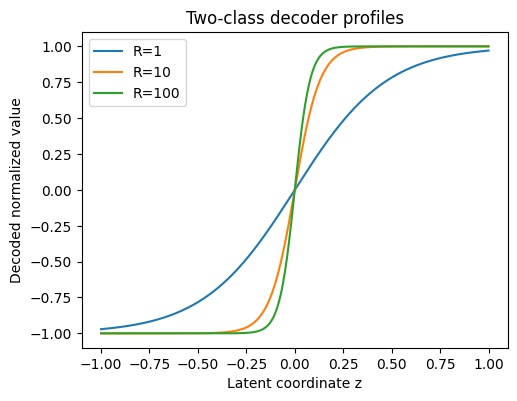

Saved /content/Fig02_a_wall_profiles.png


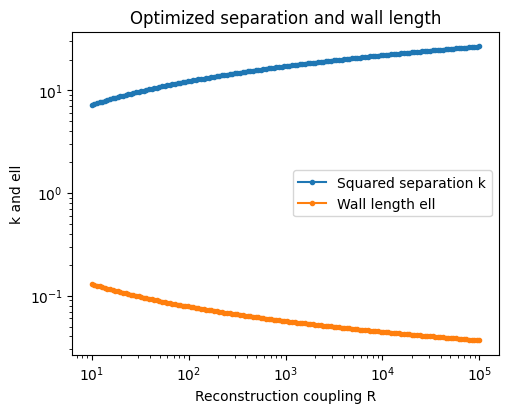

Saved /content/Fig02_b_separation_width.png


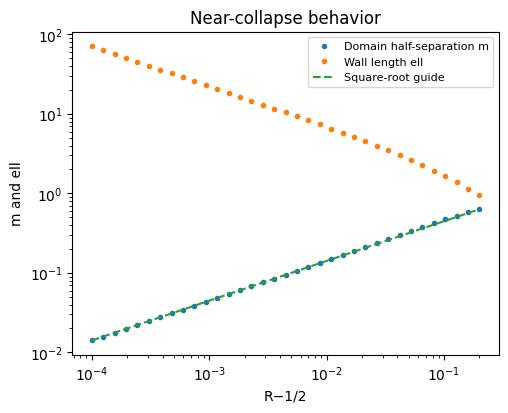

Saved /content/Fig02_c_critical_behavior.png


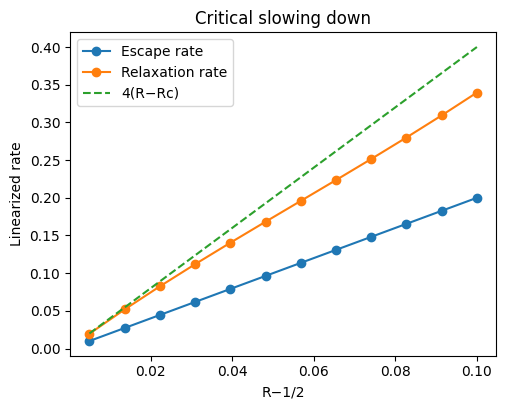

Saved /content/Fig02_d_relaxation_rates.png


In [3]:
Rs=[1.,10.,100.]
fig,ax=plt.subplots(figsize=(5.5,4.1))
z=np.linspace(-1,1,601)
for R in Rs:
    k,m,s,ell=optimum(R)
    ax.plot(z,np.tanh(z/ell),label=f'R={R:g}')
ax.set(xlabel='Latent coordinate z',ylabel='Decoded normalized value',title='Two-class decoder profiles')
ax.legend()
save_panel(fig,'Fig02_a_wall_profiles.png')

R_grid=np.geomspace(10,1e5,38 if FAST_MODE else 150)
opt=np.array([optimum(R) for R in R_grid])
fig,ax=plt.subplots(figsize=(5.5,4.2))
ax.loglog(R_grid,opt[:,0],'o-',ms=3,label='Squared separation k')
ax.loglog(R_grid,opt[:,3],'o-',ms=3,label='Wall length ell')
ax.set(xlabel='Reconstruction coupling R',ylabel='k and ell',title='Optimized separation and wall length')
ax.legend()
save_panel(fig,'Fig02_b_separation_width.png')

eps=np.geomspace(1e-4,.2,35)
near=np.array([optimum(.5+e) for e in eps])
fig,ax=plt.subplots(figsize=(5.5,4.2))
ax.loglog(eps,near[:,1],'o',ms=3,label='Domain half-separation m')
ax.loglog(eps,near[:,3],'o',ms=3,label='Wall length ell')
ax.loglog(eps,np.sqrt(2*eps),'--',label='Square-root guide')
ax.set(xlabel='R−1/2',ylabel='m and ell',title='Near-collapse behavior')
ax.legend(fontsize=8)
save_panel(fig,'Fig02_c_critical_behavior.png')

# Rates of the reduced two-variable gradient flow, not network training time.
eps=np.linspace(.005,.1,12)
escape=2*eps
relax=np.array([relaxation_rate(.5+e) for e in eps])
fig,ax=plt.subplots(figsize=(5.5,4.2))
ax.plot(eps,escape,'o-',label='Escape rate')
ax.plot(eps,relax,'o-',label='Relaxation rate')
ax.plot(eps,4*eps,'--',label='4(R−Rc)')
ax.set(xlabel='R−1/2',ylabel='Linearized rate',title='Critical slowing down')
ax.legend()
save_panel(fig,'Fig02_d_relaxation_rates.png')

## Figure 4 — class dissimilarity and latent packing

The data prototypes are class-mean 8×8 digit images. Pairwise coupling is
\[R_{ij}=\|a_i-a_j\|^2/(8\beta\sigma_x^2),\]
scaled so that the median value among ten digits is 20. A shared-width posterior is a deliberate model restriction.

Median pairwise coupling: 20.0


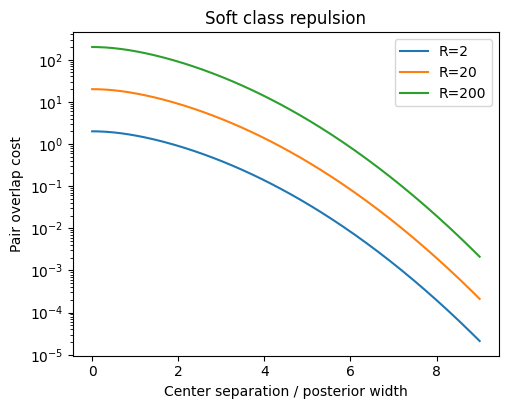

Saved /content/Fig04_a_pair_cost.png


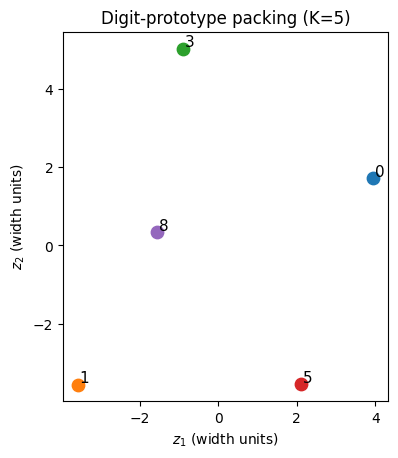

Saved /content/Fig04_c_digit_packing.png


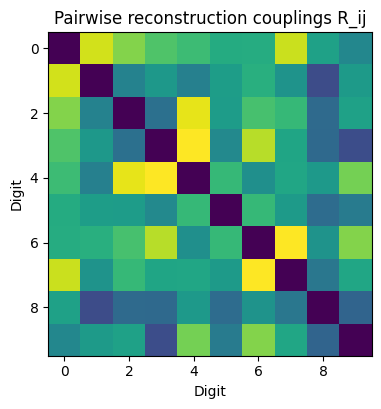

Saved /content/Fig04_e_dissimilarity.png


In [4]:
D=load_digits()
raw = (D.data / 16).astype(float)
means=np.stack([raw[D.target==k].mean(0) for k in range(10)])
sq=np.sum((means[:,None,:]-means[None,:,:])**2,axis=-1)
median=np.median(sq[np.triu_indices(10,1)])
Rij=20*sq/median
print('Median pairwise coupling:',np.median(Rij[np.triu_indices(10,1)]))

# Plot the pair overlap cost, not a stand-alone equilibrium potential.
rho=np.linspace(0,9,200)
fig,ax=plt.subplots(figsize=(5.5,4.2))
for R in [2,20,200]:
    val=np.array([integrals(t*t/4)[0] for t in rho])*R
    ax.semilogy(rho,val,label=f'R={R:g}')
ax.set(xlabel='Center separation / posterior width',ylabel='Pair overlap cost',title='Soft class repulsion')
ax.legend()
save_panel(fig,'Fig04_a_pair_cost.png')

# Best-found class-center layouts under shared isotropic widths.
def layout_loss(positions, chosen, grid_size=45):
    A=means[np.asarray(chosen)]
    X=A*np.sqrt(80/median)  # gives median R_ij near 20
    K=len(chosen)
    positions=positions.reshape(K,2)
    # Fix the translation gauge explicitly to avoid spurious drift.
    positions=positions-positions.mean(axis=0)
    moment=np.mean(np.sum(positions**2,axis=1))
    s=1/np.sqrt(1+moment)
    xs=positions*s
    t=np.linspace(-4.5,4.5,grid_size)
    Z=np.stack(np.meshgrid(t,t),axis=-1).reshape(-1,2)
    density=np.exp(-.5*np.sum(((Z[:,None,:]-xs[None,:,:])/s)**2,axis=2))/(2*np.pi*s*s*K)
    q=density.sum(axis=1).clip(1e-300)
    weights=density/q[:,None]
    decoder=weights@X
    risk=(weights*(np.sum((X[None,:,:]-decoder[:,None,:])**2,axis=-1))).sum(axis=1)
    rec=np.sum(q*risk)*(t[1]-t[0])**2/2
    kl=np.log(1+moment)
    return rec+kl

chosen=[0,1,8] if FAST_MODE else [0,1,3,5,8]
K=len(chosen); rng=np.random.default_rng(13)
best=None
for i in range(3 if FAST_MODE else 9):
    guess=rng.normal(size=(K,2))*.9
    sol=optimize.minimize(layout_loss,guess.ravel(),args=(chosen,45 if FAST_MODE else 81),method='L-BFGS-B',options={'maxiter':180})
    if best is None or sol.fun<best.fun: best=sol
pos=best.x.reshape(K,2);pos-=pos.mean(0)
fig,ax=plt.subplots(figsize=(5.5,4.8))
for i,k in enumerate(chosen):
    ax.scatter(*pos[i],s=80)
    ax.annotate(str(k),pos[i]+.045,fontsize=11)
ax.set(xlabel='$z_1$ (width units)',ylabel='$z_2$ (width units)',title=f'Digit-prototype packing (K={K})')
ax.set_aspect('equal')
save_panel(fig,'Fig04_c_digit_packing.png')

fig,ax=plt.subplots(figsize=(5.5,4.2))
ax.imshow(Rij,cmap='viridis')
ax.set(xlabel='Digit',ylabel='Digit',title='Pairwise reconstruction couplings R_ij')
save_panel(fig,'Fig04_e_dissimilarity.png')

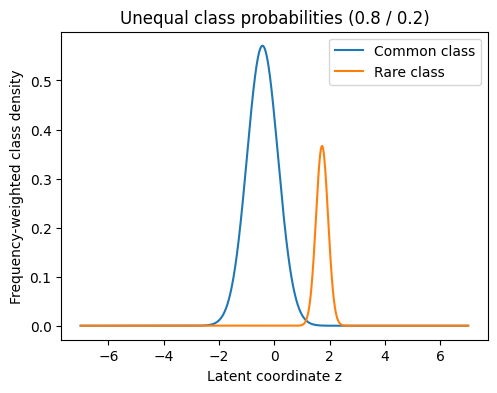

Saved /content/Fig04_b_unequal_frequencies.png


In [5]:

# Figure 4(b): exact unequal-frequency two-class posterior optimization.
z=np.linspace(-7,7,3501);dz=z[1]-z[0]
weights=np.array([.8,.2]);chi=40.0
def unequal_loss(par):
    mu=par[:2];s=np.exp(par[2:]);
    q=weights[:,None]*np.exp(-.5*((z[None,:]-mu[:,None])/s[:,None])**2)/(np.sqrt(2*np.pi)*s[:,None])
    rec=chi*np.sum(q[0]*q[1]/np.maximum(q.sum(axis=0),1e-300))*dz
    kl=np.sum(weights*.5*(mu**2+s**2-1-2*np.log(s)))
    return rec+kl
candidates=[optimize.minimize(unequal_loss,p,method='Nelder-Mead',options={'maxiter':4000})
            for p in [[-.5,1.8,-.5,-1.2],[-.8,2.,-.4,-2.]]]
best=min(candidates,key=lambda result:result.fun)
mu=best.x[:2];s=np.exp(best.x[2:])
fig,ax=plt.subplots(figsize=(5.5,4))
for j,name in enumerate(['Common class','Rare class']):
    ax.plot(z,weights[j]*np.exp(-.5*((z-mu[j])/s[j])**2)/(np.sqrt(2*np.pi)*s[j]),label=name)
ax.set(xlabel='Latent coordinate z',ylabel='Frequency-weighted class density',title='Unequal class probabilities (0.8 / 0.2)')
ax.legend();save_panel(fig,'Fig04_b_unequal_frequencies.png')


### Figure 4(d): one-dimensional ordering diagnostic

This simplified panel evaluates the **exact class-aggregate risk at equally spaced candidate locations**, optimizing their common gap. It is a readable **ordering diagnostic**, not a replacement for the source Figure 4(d) calculation, which independently optimized all six class coordinates and used 360 non-reversed configurations.

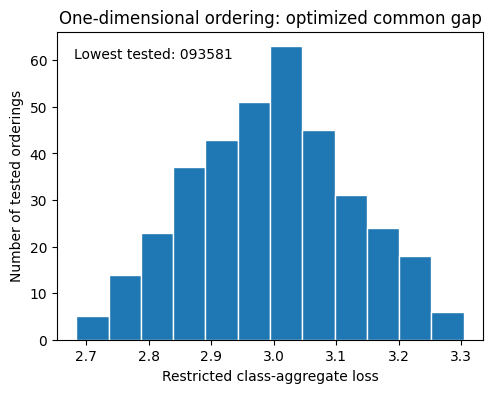

Saved /content/Fig04_d_orderings_diagnostic.png


In [6]:

from scipy import stats
from itertools import permutations
selected=[0,1,3,5,8,9]
X=means[selected]*np.sqrt(80/median)
freq=np.bincount(D.target,minlength=10)[selected].astype(float)
freq/=freq.sum()
pair_grid=np.linspace(-8,8,901 if FAST_MODE else 2001)
dt=pair_grid[1]-pair_grid[0]
def candidate_order_loss(order, gap):
    u=np.empty(len(order))
    u[list(order)]=gap*(np.arange(len(order))-(len(order)-1)/2)
    u=u-np.dot(freq,u)
    moment=np.dot(freq,u*u)
    s=1/np.sqrt(1+moment)
    q=freq[None,:]*stats.norm.pdf(pair_grid[:,None],u[None,:],1.)
    totals=q.sum(1).clip(1e-300)
    weighted=q@X
    sqX=np.sum(X**2,axis=1)
    risk=np.sum(q*sqX[None,:],axis=1)-(weighted*weighted).sum(1)/totals
    return .5*np.sum(risk)*dt+.5*np.log1p(moment)
# Symmetry removes reversed duplicates: 360 possible orderings.
orders=[p for p in permutations(range(6)) if p[0]<p[-1]]
if FAST_MODE: orders=orders[:40]   # small diagnostic sample, not full enumeration
vals=[]
for order in orders:
    res=optimize.minimize_scalar(lambda d:candidate_order_loss(order,d),bounds=(.5,3.8),method='bounded')
    vals.append(res.fun)
bestorder=orders[int(np.argmin(vals))]
fig,ax=plt.subplots(figsize=(5.5,4))
ax.hist(vals,bins=12,edgecolor='white')
ax.set(xlabel='Restricted class-aggregate loss',ylabel='Number of tested orderings',
       title='One-dimensional ordering: optimized common gap')
ax.text(.04,.95,'Lowest tested: '+''.join(str(selected[i]) for i in bestorder),
        transform=ax.transAxes,va='top')
save_panel(fig,'Fig04_d_orderings_diagnostic.png')


## Figure 5 — optimized rare-state prototypes

This is a direct, non-amortized one-dimensional Gaussian posterior optimization. We construct the circle, square, rounded square, and rhombus using NumPy. The optimizer evaluates the **conditional-mean reconstruction risk and Gaussian KL**, using analytic gradients. The original manuscript's full regime diagram uses multiple restarts, so the fast regime panel is explicitly illustrative.

In [7]:
"""Figure 5(d): original notebook's Gaussian-encoder model and state definition.
Only the prototype-coordinate evaluation is accelerated: thin QR preserves every
prototype inner product, norm, squared reconstruction error, and analytical gradient.
The full 40x40 prototypes remain available for decoding and regime classification.
Original L-BFGS-B bounds/options, 3000-point latent grid, and 14 starts are retained.
"""
from pathlib import Path
import json, time, hashlib
import numpy as np
from scipy.optimize import minimize
from scipy.ndimage import gaussian_filter
P = dict(rare_G=3000, rare_starts=[0.0, 0.15, -0.15, 2.0, -2.0, -0.95, 0.95])

class Enc:
    # nonparametric diagonal-Gaussian encoder with the optimal decoder on a latent grid (units 2*beta*sigma^2 = 1)
    def __init__(s, X, w, d, L=4.5, G=None):
        s.full_X = X.copy(); s.X = np.linalg.qr(X.T, mode="reduced")[1].T; X = s.X; s.w = w / w.sum(); s.n = len(X); s.d = d; G = G or {1: 2400, 2: 201}[d]
        ax = np.linspace(-L, L, G); s.dV = (ax[1] - ax[0])**d; s.lsmin = np.log(2.5 * (ax[1] - ax[0]))
        s.Z = np.stack(np.meshgrid(*([ax] * d), indexing='ij'), -1).reshape(-1, d); s.c0 = np.sum(s.w * np.sum(X**2, 1))
    def unpack(s, p): k = s.n * s.d; return p[:k].reshape(s.n, s.d), p[k:].reshape(s.n, s.d)
    def dens(s, mu, sg, Z):
        D = Z[None] - mu[:, None]; u = D / sg[:, None]
        return D, u, np.exp(-0.5 * np.sum(u**2, -1)) / np.prod(np.sqrt(2 * np.pi) * sg, 1)[:, None]
    def f(s, p):
        mu, ls = s.unpack(p); sg = np.exp(ls); D, u, q = s.dens(mu, sg, s.Z)
        qb = s.w @ q + 1e-300; F = (q * s.w[:, None]).T @ s.X; fz = F / qb[:, None]
        rec = s.c0 - np.sum(np.sum(F**2, 1) / qb) * s.dV
        kl = np.sum(s.w[:, None] * 0.5 * (mu**2 + sg**2 - 1 - 2 * ls))
        G = -(s.dV) * (2 * (s.X @ fz.T) - np.sum(fz**2, 1)[None]); Gq = G * q * s.w[:, None]
        gmu = np.einsum('nz,nzk->nk', Gq, u) / sg + s.w[:, None] * mu
        gls = np.einsum('nz,nzk->nk', Gq, u**2 - 1) + s.w[:, None] * (sg**2 - 1)
        return rec + kl, np.r_[gmu.ravel(), gls.ravel()]
    def run(s, mu0, ls0, it=6000):
        bnd = [(None, None)] * (s.n * s.d) + [(s.lsmin, 1.0)] * (s.n * s.d)
        r = minimize(s.f, np.r_[mu0.ravel(), np.maximum(ls0.ravel(), s.lsmin + 0.01)], jac=True, method='L-BFGS-B', bounds=bnd,
                     options={'maxiter': it, 'maxfun': 2 * it, 'gtol': 1e-9})
        s.last_result = r
        mu, ls = s.unpack(r.x); return r.fun, mu, ls
    def decode(s, mu, ls, zq):
        _, _, q = s.dens(mu, np.exp(ls), zq); q = q * s.w[:, None]; return (q.T @ s.full_X) / q.sum(0)[:, None]


n_px = 40; c0 = (n_px - 1) / 2; yy, xx = np.mgrid[0:n_px, 0:n_px] - c0
superellipse = lambda p, a: (np.abs(xx / a)**p + np.abs(yy / a)**p <= 1).astype(float)
aa = lambda img: gaussian_filter(img, 0.6)
A_img, B_img = aa(superellipse(2, 9.0)), aa(superellipse(60, 13.0)); d_ = (B_img - A_img).ravel()
best = None
for p in np.arange(2.2, 6.01, 0.2):            # superellipse closest to the midpoint of the A-B segment
    for a in np.arange(9.5, 13.01, 0.1):
        C = aa(superellipse(p, a)).ravel(); t = (C - A_img.ravel()) @ d_ / (d_ @ d_)
        sc = abs(t - 0.5) + np.sum((C - A_img.ravel() - t * d_)**2) / (d_ @ d_)
        if best is None or sc < best[0]: best = (sc, p, a)
rhombus = aa(((np.abs(xx) / 4.5 + np.abs(yy) / 18.5) <= 1).astype(float))
SHAPES = np.stack([A_img, B_img, aa(superellipse(best[1], best[2])), rhombus])
def geometry(S, i):
    A, B = S[0].ravel(), S[1].ravel(); d = B - A
    t = (S[i].ravel() - A) @ d / (d @ d); h2 = np.sum((S[i].ravel() - A - t * d)**2) / (d @ d); return t, h2
for i, nm in [(2, 'rounded square'), (3, 'rhombus')]:
    t, h2 = geometry(SHAPES, i); print(f'{nm:15s} t = {t:.3f}, h^2/|aA-aB|^2 = {h2:.3f}')

def solve_rare(chi, ci, pi, S=SHAPES):
    G = P['rare_G']; sc = np.sqrt(chi / np.sum((S[1] - S[0])**2)); idx = [0, 1] + ([ci] if ci else [])
    X = np.stack([S[i].ravel() for i in idx]) * sc; w = np.array([(1 - pi) / 2, (1 - pi) / 2] + ([pi] if ci else []))
    e = Enc(X, w, 1, L=5, G=G); bst = None; attempts=[]; chosen=-1
    for zc in (P['rare_starts'] if ci else [0]):
        for lsc in [np.log(0.03), np.log(0.15)]:
            mu0 = np.array([[-0.95], [0.95]] + ([[zc]] if ci else [])); ls0 = np.array([[np.log(0.3)]] * 2 + ([[lsc]] if ci else []))
            r = e.run(mu0, ls0, it=4000)
            attempts.append(dict(initial_rare_mean=float(zc), initial_rare_width=float(np.exp(lsc)),
                loss=float(r[0]), success=bool(e.last_result.success), status=int(e.last_result.status),
                iterations=int(e.last_result.nit), evaluations=int(e.last_result.nfev),
                gradient_max=float(np.max(np.abs(e.last_result.jac))), message=str(e.last_result.message)))
            if bst is None or r[0] < bst[0]: bst = r; chosen=len(attempts)-1
            if not ci: break
    L, mu, ls = bst; m = mu[:, 0]; sg = np.exp(ls[:, 0]); zz = e.Z[:, 0]
    q = w[:, None] * np.exp(-0.5 * ((zz[None] - m[:, None]) / sg[:, None])**2) / sg[:, None]; r = q / q.sum(0)
    rAB = r[1] / (r[0] + r[1]); zw = zz[np.argmin(np.abs(rAB - 0.5))]
    out = dict(chi=chi, ci=ci, pi=pi, L=L, m=m, sg=sg, zw=zw, sc=sc, w=w, X=X, attempts=attempts, chosen=chosen)
    if ci:
        xh = e.decode(mu, ls, mu[2:3])[0] / sc
        err = np.sum((xh - S[ci].ravel())**2) / np.sum((S[ci] - 0.5 * (S[0] + S[1]))**2)
        out['err'] = err; out['rCmax'] = r[2].max()
        between = min(m[0], m[1]) < m[2] < max(m[0], m[1])
        # rule used for Figure 5: is the decoded rare class close to its prototype?
        if abs(m[1] - m[0]) < 0.3: st = 'collapsed'
        elif err < 0.5: st = 'layer' if between else 'tail island'
        else: st = 'adsorbed' if abs(m[2] - zw) < min(abs(m[2] - m[0]), abs(m[2] - m[1])) else 'dissolved'
        out['state'] = st
        # rule used for Figure S5f: does the posterior of the rare class dominate anywhere?
        if r[2].max() > 0.5: out['state_dom'] = 'layer' if between else 'tail island'
        else: out['state_dom'] = 'adsorbed' if abs(m[2] - zw) < 0.25 * abs(m[1] - m[0]) else 'dissolved'
    return out



rounded square  t = 0.500, h^2/|aA-aB|^2 = 0.188
rhombus         t = 0.029, h^2/|aA-aB|^2 = 0.371


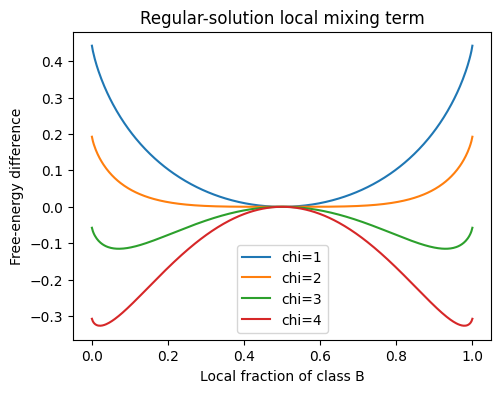

Saved /content/Fig05_a_local_mixing.png


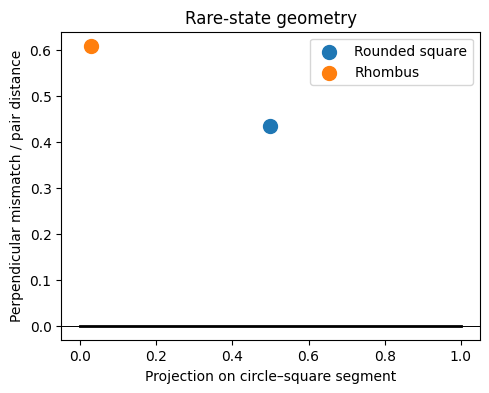

Saved /content/Fig05_b_rare_geometry.png


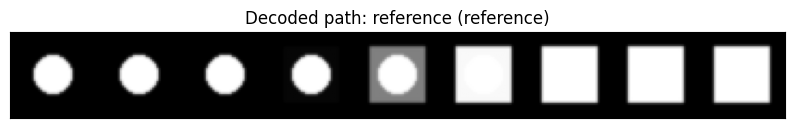

Saved /content/Fig05_c_reference.png


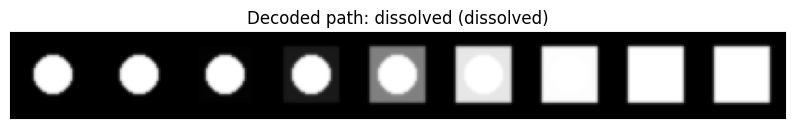

Saved /content/Fig05_c_dissolved.png


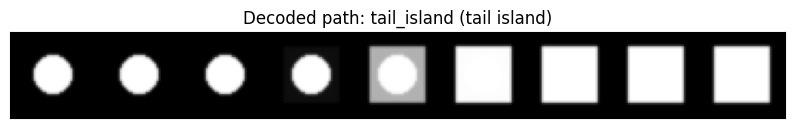

Saved /content/Fig05_c_tail_island.png


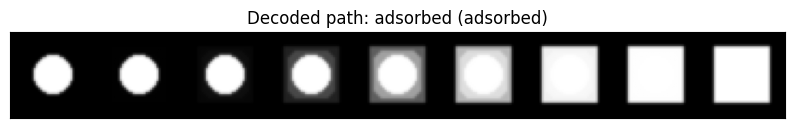

Saved /content/Fig05_c_adsorbed.png


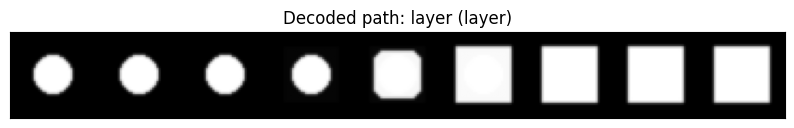

Saved /content/Fig05_c_layer.png
Regime row 1/18 complete
Regime row 2/18 complete
Regime row 3/18 complete
Regime row 4/18 complete
Regime row 5/18 complete
Regime row 6/18 complete
Regime row 7/18 complete
Regime row 8/18 complete
Regime row 9/18 complete
Regime row 10/18 complete
Regime row 11/18 complete
Regime row 12/18 complete
Regime row 13/18 complete
Regime row 14/18 complete
Regime row 15/18 complete
Regime row 16/18 complete
Regime row 17/18 complete
Regime row 18/18 complete


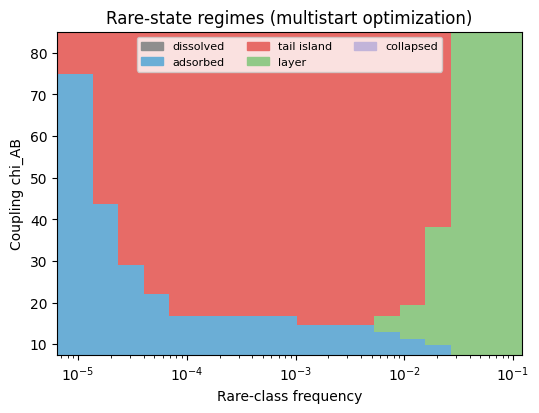

Saved /content/Fig05_d_regime_map.png


In [8]:
if FAST_MODE:
    P['rare_G'] = 900
    P['rare_starts'] = [0.0, -0.8, 0.8]  # six starts instead of fourteen

# Plot the elementary local Flory–Huggins free energy.
r=np.linspace(1e-4,1-1e-4,400)
fig,ax=plt.subplots(figsize=(5.4,4.0))
for chi in [1,2,3,4]:
    f=chi*r*(1-r)+r*np.log(r)+(1-r)*np.log(1-r)
    ax.plot(r,f-f[200],label=f'chi={chi}')
ax.set(xlabel='Local fraction of class B',ylabel='Free-energy difference',title='Regular-solution local mixing term')
ax.legend()
save_panel(fig,'Fig05_a_local_mixing.png')

fig,ax=plt.subplots(figsize=(5.4,4.0))
for i,name in [(2,'Rounded square'),(3,'Rhombus')]:
    t,h2=geometry(SHAPES,i)
    ax.scatter(t,np.sqrt(h2),s=100,label=name)
ax.axhline(0,color='k',lw=.7)
ax.plot([0,1],[0,0],'k-',lw=2)
ax.set(xlabel='Projection on circle–square segment',ylabel='Perpendicular mismatch / pair distance',title='Rare-state geometry')
ax.legend()
save_panel(fig,'Fig05_b_rare_geometry.png')

# Five genuinely optimized decoded paths. These are computed independently.
case_settings=[('reference',None,0.,40.),('dissolved',3,.001,12.),
               ('tail_island',3,.03,40.),('adsorbed',2,.03,8.),('layer',2,.03,40.)]
def decode_rare(result,coords):
    m=result['m'];s=result['sg'];w=result['w'];X=result['X'];scale=result['sc']
    q=w[:,None]*np.exp(-.5*((coords[None,:]-m[:,None])/s[:,None])**2)/s[:,None]
    return ((q.T@X)/q.sum(axis=0)[:,None]/scale).reshape(-1,40,40)
for name,kind,fraction,chi in case_settings:
    res=solve_rare(chi,kind,fraction)
    path=np.linspace(min(res['m'][:2]),max(res['m'][:2]),9)
    images=decode_rare(res,path)
    canvas=np.concatenate(images,axis=1)
    fig,ax=plt.subplots(figsize=(10,1.8))
    ax.imshow(canvas,cmap='gray',vmin=0,vmax=1)
    ax.set(xticks=[],yticks=[],title=f'Decoded path: {name} ({res.get("state","reference")})')
    save_panel(fig,f'Fig05_c_{name}.png')

# Reoptimize every point. Do not interpolate or replay a stored regime diagram.
chi_values=np.geomspace(8,80,5 if FAST_MODE else 18)
freq_values=np.geomspace(1e-5,.1,5 if FAST_MODE else 18)
states=['dissolved','adsorbed','tail island','layer','collapsed']
regimes=np.zeros((len(chi_values),len(freq_values)),dtype=int)
for j,chi in enumerate(chi_values):
    for i,frac in enumerate(freq_values):
        res=solve_rare(float(chi),2,float(frac))
        regimes[j,i]=states.index(res['state'])
    print(f'Regime row {j+1}/{len(chi_values)} complete')
fig,ax=plt.subplots(figsize=(6.0,4.2))
from matplotlib.colors import ListedColormap,BoundaryNorm
cmap=ListedColormap(['#8e8e8e','#6baed6','#e76b67','#91c987','#c2b4d9'])
ax.pcolormesh(freq_values,chi_values,regimes,shading='nearest',cmap=cmap,vmin=-.5,vmax=4.5)
ax.set(xscale='log',xlabel='Rare-class frequency',ylabel='Coupling chi_AB',title='Rare-state regimes (multistart optimization)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=cmap(i),label=state) for i,state in enumerate(states)],loc='upper center',ncol=3,fontsize=8)
save_panel(fig,'Fig05_d_regime_map.png')